In [1]:
import numpy as np
import matplotlib.pyplot as plt

YIELD = 10000 # фотонов/МэВ

In [2]:
class PMT:
    def __init__(self, pos, r):
        self.pos = pos
        self.r = r
    
    def n_photoelectrons(self, a):
        return np.random.poisson(a)

In [3]:
class Detector:
    def __init__(self, R, N, r, a):
        self.R = R
        self.N = N
        self.r = r
        self.a = a
        self.pmts = []
        self._make_pmts()
    
    def _make_pmts(self):
        i = np.arange(self.N) + 0.5
        phi = np.arccos(1 - 2*i/self.N)
        theta = np.pi * (1 + 5**0.5) * i
        x = self.R * np.sin(phi) * np.cos(theta)
        y = self.R * np.sin(phi) * np.sin(theta)
        z = self.R * np.cos(phi)
        
        for k in range(self.N):
            self.pmts.append(PMT(np.array([x[k], y[k], z[k]]), self.r))
    
    def hit_point(self, origin, direction):
        a = np.dot(direction, direction)
        b = 2 * np.dot(origin, direction)
        c = np.dot(origin, origin) - self.R**2
        
        disc = b**2 - 4*a*c
        if disc < 0:
            return None
        t = (-b + np.sqrt(disc)) / (2*a)
        if t < 0:
            return None
        
        return origin + t * direction
    
    def find_pmt(self, point):
        for i, p in enumerate(self.pmts):
            if np.linalg.norm(point - p.pos) <= p.r:
                return i
        return -1

In [4]:
class Source:
    def __init__(self, Y=YIELD):
        self.Y = Y
    
    def n_photons(self, E):
        return np.random.poisson(self.Y * E)
    
    def directions(self, N):
        phi = np.random.uniform(0, 2*np.pi, N)
        cos_t = np.random.uniform(-1, 1, N)
        sin_t = np.sqrt(1 - cos_t**2)
        x = sin_t * np.cos(phi)
        y = sin_t * np.sin(phi)
        z = cos_t
        return np.array([x, y, z])
    
    def event(self, E):
        N = self.n_photons(E)
        if N == 0:
            return np.zeros((3, 0))
        return self.directions(N)

In [5]:
det = Detector(R=2.0, N=40, r=0.1, a=0.5)
src = Source()

source_pos = np.array([0.0, 0.0, 0.0])
E_event = 1.0
N_photons = src.n_photons(E_event)
directions = src.directions(N_photons)

print(f"Событие с E = {E_event} МэВ")
print(f"Всего фотонов: {N_photons}")

# массив для подсчёта фотоэлектронов по каждому ФЭУ
n_pe_per_pmt = np.zeros(det.N, dtype=int)

for i in range(N_photons):
    d = directions[:, i]
    hit = det.hit_point(source_pos, d)
    if hit is None:
        continue
    pmt_idx = det.find_pmt(hit)
    if pmt_idx == -1:
        continue # фотон улетел в «щель» между ФЭУ
    n_pe = det.pmts[pmt_idx].n_photoelectrons(det.a)
    n_pe_per_pmt[pmt_idx] += n_pe

Q_total = n_pe_per_pmt.sum()

print(f"Суммарный собранный заряд Q = {Q_total} фотоэлектронов")
print(f"Ожидаемое значение Q = {det.a * src.Y * E_event * (det.N * det.r**2 / det.R**2):.0f}")

Событие с E = 1.0 МэВ
Всего фотонов: 9941
Суммарный собранный заряд Q = 118 фотоэлектронов
Ожидаемое значение Q = 500


In [6]:
def simulate_event(det, src, E, source_pos=None):
    if source_pos is None:
        source_pos = np.zeros(3)
    N_photons = src.n_photons(E)
    directions = src.directions(N_photons)
    n_pe = np.zeros(det.N, dtype=int)
    for i in range(N_photons):
        d = directions[:, i]
        hit = det.hit_point(source_pos, d)
        if hit is None:
            continue
        pmt_idx = det.find_pmt(hit)
        if pmt_idx == -1:
            continue
        n_pe[pmt_idx] += det.pmts[pmt_idx].n_photoelectrons(det.a)
    
    return n_pe.sum()

N_events = 200
charges = np.array([simulate_event(det, src, E_event) for _ in range(N_events)])
Q_mean = charges.mean()
Q_std = charges.std()
Q_from_task = det.a * src.Y * E_event * (det.N * det.r**2 / det.R**2) # формула из условия задачи
Q_another = det.a * src.Y * E_event * (det.N * det.r**2 / (4 * det.R**2)) # свой вариант

print(f"Средний заряд по {N_events} событиям {Q_mean:.1f} ± {Q_std:.1f}")
print()
print(f"Формула из условия (N*r^2 / R^2): {Q_from_task:.1f}")
print(f"Свой вариант (N*r^2 / (4*R^2)): {Q_another:.1f}")
print()
print(f"Q_mean / Q_task = {Q_mean / Q_from_task:.3f}")
print(f"Q_mean / Q_correct = {Q_mean / Q_another:.3f}")

Средний заряд по 200 событиям 124.1 ± 13.8

Формула из условия (N*r^2 / R^2): 500.0
Свой вариант (N*r^2 / (4*R^2)): 125.0

Q_mean / Q_task = 0.248
Q_mean / Q_correct = 0.992


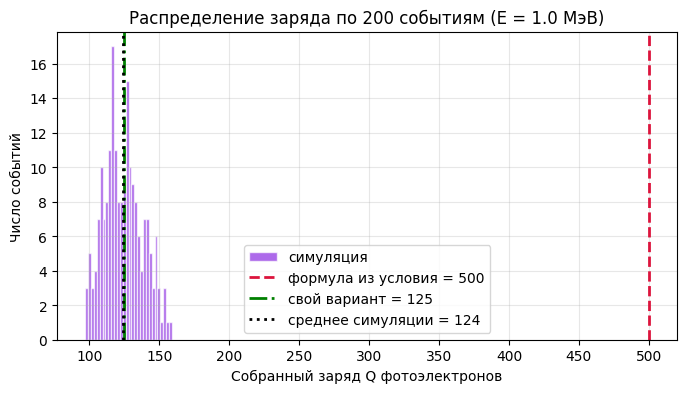

In [7]:
plt.figure(figsize=(8, 4))
plt.hist(charges, bins=30, alpha=0.7, color='blueviolet', edgecolor='white', label='симуляция')
plt.axvline(Q_from_task, color='crimson', linestyle='--', linewidth=2, label=f'формула из условия = {Q_from_task:.0f}')
plt.axvline(Q_another, color='green', linestyle='-.', linewidth=2, label=f'свой вариант = {Q_another:.0f}')
plt.axvline(Q_mean, color='black', linestyle=':', linewidth=2, label=f'среднее симуляции = {Q_mean:.0f}')
plt.xlabel('Собранный заряд Q фотоэлектронов')
plt.ylabel('Число событий')
plt.title(f'Распределение заряда по {N_events} событиям (E = {E_event} МэВ)')
plt.legend()
plt.grid(alpha=0.3)
plt.show()